# Example use of the Cell class

In [9]:
"""Example use of the Cell class"""

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from lattice_cell import LatticeCell

In [10]:
plt.rc('axes', labelsize=12)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=10)    # legend fontsize

The class has a set of default paramaters (corresponds to RCS2).
You can provide the class with two files:
- a geometric file: same file parameter that you would give to the geometry class
- a complementary file that contains information necessary to calculate the beam size, QP aperture, RF length necessary...

An example of the complementary file is given in the following, for RCS 2:

In [11]:
default_para = {
        'n_sigma' : 6, # Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta' : 5e-3, # Max dispersion in energy of the beam
        'emitt_norm' : 25e-6, # Normalized emittance
        'n_cav' : 380, # Total number of cavity
        'l_cav' : 1.2474, # Length of 1 cavity
        'mu' : np.pi/2, # Phase advance per cell
        'apert_qp_min' : 30e-3, # Min aperture size (diam) to be taken for QP
        'dx' : 10e-3, # Extra radius length to be taken to fit vacuum chambers
        'Bpole' : 1, # Max field on QP pole
        'nb_bloc' : 1, # Number of bloc per pattern
    }

In [12]:
default_geo = {
   'type': 'hybrid', # Type of the RCS
   'circumference': 5990, # Circumference
   'injection_energy': 313.830e9, # Injection energy
   'extraction_energy': 750e9, # Extraction energy
   'length_short_insertion': 2.5, # Length insertion for QP/SXT
   'dipole_spacing': 0.3, # Spacing between two dipoles
   'nb_RF_section': 24, # Total nb of RF sections
   'nb_arc': 26, # Total nb of arc
   'nb_cell_arc': 10, # Nb of cells per arc
   'dipoles': { # Dipole field and shape of the ramp
      'BNC': [1.8, 'linear'],
	   'BSC': 10.0
   },
   'filling_ratio': 0.85, # Filling ratio of the arc wrt to the circumference
   'filling_ratio_RF': 0.4, # Filling ratio of the RF cavities in the RF section
   'pattern': ['BSC', 'BNC', 'BSC', 'BSC', 'BNC', 'BSC'] # Pattern of a half-cell
}

In [13]:
cell = LatticeCell(file_input_geo = default_geo)

Apertures computed for 1 bloc of dipole


/mnt/c/muco/mucol/class_geometry/ring_geometry/ring_geometry.py:330: UserWarning: Number of cells per arc was optimised from 10 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


The class computes the optimum quadrupole and cell length for a RCS. 
The aperture of the QP is adapted to fit the beam size. 
The aperture in the NC and SC dipole is calculated for the optimum solution. 

In [14]:
print('Optimal number of cell', cell.nc_opt)
print('Optimal cell length ', cell.lcell_opt)
print('Optimal quad length', cell.lquad_opt)
print('Filling ratio of arc', cell.rcs_opt.filling_ratio)
print('Momentum compaction factor [1e-4]', cell.mcf * 1e4)
print('Aperture in pulsed dipoles [mm]', cell.width_nc_opt * 1e3)
print('Aperture in steady dipoles [mm]', cell.width_sc_opt * 1e3)

Optimal number of cell 4.0
Optimal cell length  53.038346153846156
Optimal quad length 3.4857844637192676
Filling ratio of arc 0.9208661101836394
Momentum compaction factor [1e-4] 16.10557175475354
Aperture in pulsed dipoles [mm] 53.31582634112268
Aperture in steady dipoles [mm] 16.649665934306423


We can visualize the optimum by plotting the possible solutions of cell length $L_c$ and quad length $L_{qp}$. 
The possible solutions are the one that 'fits' in the circumference of the given RCS.

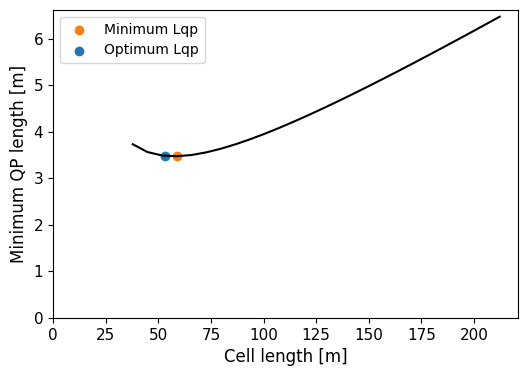

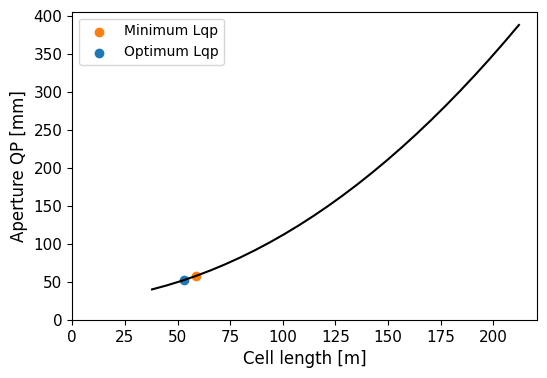

In [15]:
plt.figure(figsize=(6,4))
plt.plot(cell.lcell_sol, cell.lquad_sol, color='k')
plt.scatter(cell.lcell_sol[np.argmin(cell.lquad_sol)], cell.lquad_min, color='tab:orange',
            label='Minimum Lqp')
plt.scatter(cell.lcell_opt, cell.lquad_opt, color='tab:blue', label='Optimum Lqp')
plt.xlabel('Cell length [m]')
plt.ylabel('Minimum QP length [m]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(cell.lcell_sol, 2 * cell.size_beam_sol * 1e3, color='k')
plt.scatter(cell.lcell_sol[np.argmin(cell.lquad_sol)], 2 * 1e3 * cell.size_beam_sol[
    np.argmin(cell.lquad_sol)], color='tab:orange',label='Minimum Lqp')
plt.scatter(cell.lcell_opt, cell.apert_diam * 1e3, color='tab:blue', label='Optimum Lqp' )
plt.xlabel('Cell length [m]')
plt.ylabel('Aperture QP [mm]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
plt.legend()
plt.show()

The minimum Lqp point corresponds to the cell length that minimizes the quadrupole length. 

Having a discrete number of cells per arc does not allow to have a set of continuous solutions for $L_c$: 
the optimum $L_{qp}$ corresponds to a cell length that gives an integer number of cells.

For all the possible cell lengths, we plot the corresponding number of cells per arc in which it fits. 

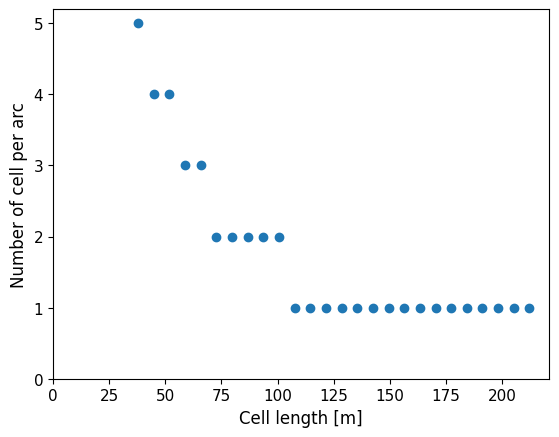

In [16]:
plt.figure()
plt.scatter(cell.lcell_sol, cell.nc_sol)
plt.xlabel('Cell length [m]')
plt.ylabel('Number of cell per arc')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
plt.show()

The aperture in the NC and SC dipoles only depend on the number of cells per arc $n_c$. The beam size is determined by the cell length $L_c$ (and we only have one $L_c$ for each $n_c$: $L_c = L_{arc}/n_c$). The excursion in the dipoles only depends on $n_c$. 

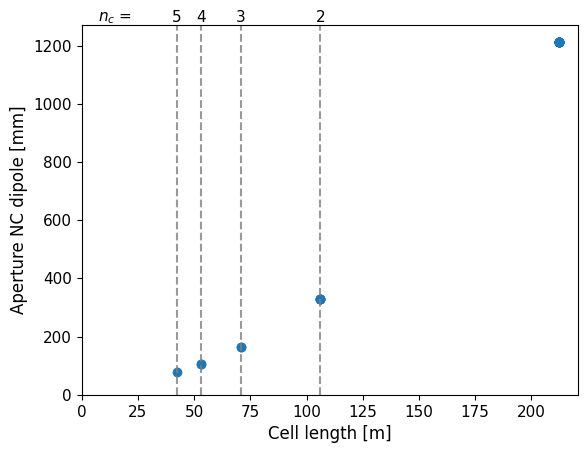

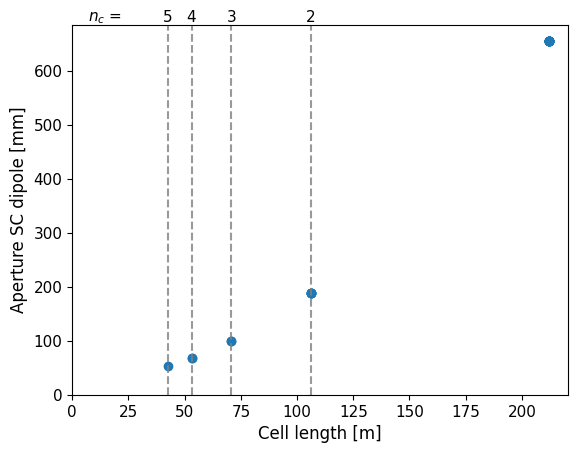

In [17]:
plt.figure()
plt.scatter(cell.lcell_geo[:-1], cell.apert_nc_geo[:-1] * 1e3)

y_leg=plt.ylim()[1]
for l_cell in pd.unique(cell.lcell_geo)[:-1]:
    plt.axvline(x=l_cell, linestyle='dashed', alpha=0.8, color='grey')
    plt.text(l_cell, y_leg * 1.02, f'{int(cell.arc_length/l_cell)}', ha='center', va='center',
                fontsize=11, color='black',fontdict={'fontname':'DejaVu Sans'})
plt.text(15, y_leg * 1.02, '$n_c$ = ', ha='center', va='center', fontsize=11, color='black',
            fontdict={'fontname':'DejaVu Sans'})
plt.xlabel('Cell length [m]')
plt.ylabel('Aperture NC dipole [mm]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
plt.show()

plt.figure()
plt.scatter(cell.lcell_geo[:-1], cell.apert_sc_geo[:-1] * 1e3)
y_leg=plt.ylim()[1]
for l_cell in pd.unique(cell.lcell_geo)[:-1]:
    plt.axvline(x=l_cell, linestyle='dashed', alpha=0.8, color='grey')
    plt.text(l_cell, y_leg * 1.02, f'{int(cell.arc_length/l_cell)}', ha='center', va='center',
                fontsize=11, color='black', fontdict={'fontname':'DejaVu Sans'})
plt.text(15, y_leg * 1.02, '$n_c$ = ', ha='center', va='center', fontsize=11, color='black',
            fontdict={'fontname':'DejaVu Sans'})
plt.xlabel('Cell length [m]')
plt.ylabel('Aperture SC dipole [mm]')
plt.ylim(ymin=0)
plt.xlim(xmin=0)
plt.show()

The beam size and the excursion increases with $L_c$. In terms of aperture, the larger $n_c$ the smaller aperture we will need.